In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
population = np.random.exponential(
    scale=50,
    size=100000
)

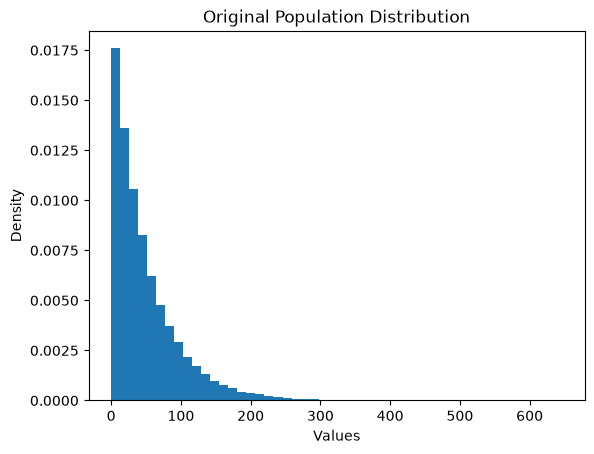

In [3]:
# Visualize the population
plt.hist(population, bins=50, density=True)

plt.title("Original Population Distribution")
plt.xlabel("Values")
plt.ylabel("Density")

plt.show()

In [4]:
# Take random samples and calculate their means
sample_size = 30
number_of_samples = 1000

sample_means = []

for i in range(number_of_samples):

    sample = np.random.choice(
        population,
        size=sample_size
    )

    sample_mean = np.mean(sample)

    sample_means.append(sample_mean)

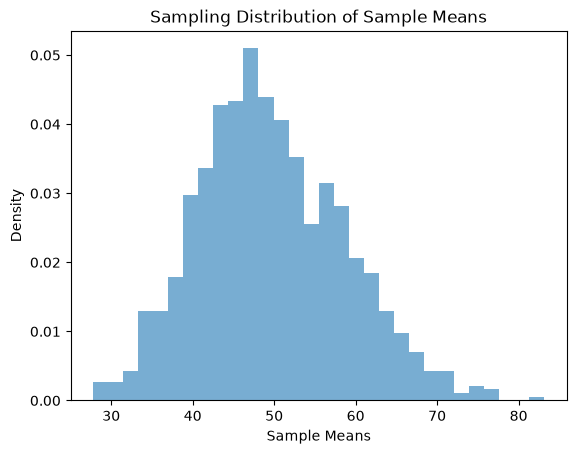

In [5]:
# Visualize the sampling distribution
plt.hist(
    sample_means,
    bins=30,
    density=True,
    alpha=0.6
)

plt.title("Sampling Distribution of Sample Means")
plt.xlabel("Sample Means")
plt.ylabel("Density")

plt.show()

In [6]:
# Verify CLT using SciPy
population_mean = np.mean(population)
sample_mean = np.mean(sample_means)
population_std = np.std(population)
standard_error = population_std / np.sqrt(sample_size)

print("Population Mean:", population_mean)
print("Mean of Sample Means:", sample_mean)
print("Standard Error:", standard_error)
print("Theoretical Standard Error:", standard_error)

Population Mean: 49.873499939373666
Mean of Sample Means: 49.6754180418075
Standard Error: 9.108971675842714
Theoretical Standard Error: 9.108971675842714


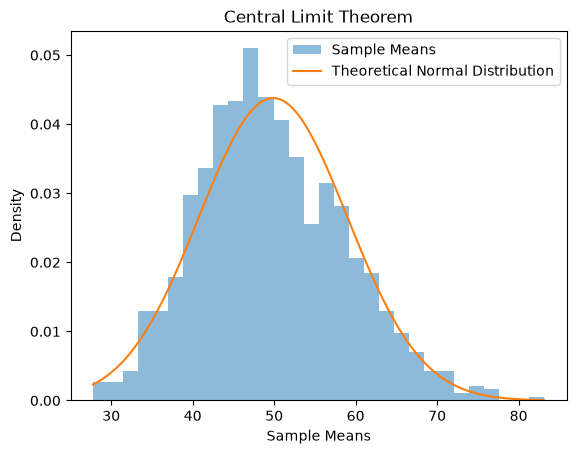

In [7]:
# Use SciPy to compare with a Normal Distribution
x = np.linspace(
    min(sample_means),
    max(sample_means),
    100
)

normal_distribution = stats.norm.pdf(
    x,
    loc=population_mean,
    scale=standard_error
)

plt.hist(
    sample_means,
    bins=30,
    density=True,
    alpha=0.5,
    label="Sample Means"
)

plt.plot(
    x,
    normal_distribution,
    label="Theoretical Normal Distribution"
)

plt.title("Central Limit Theorem")
plt.xlabel("Sample Means")
plt.ylabel("Density")

plt.legend()
plt.show()

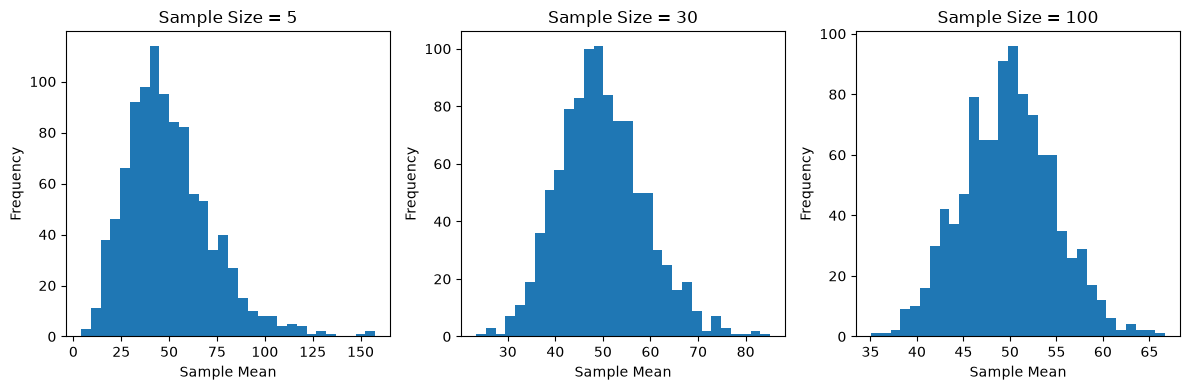

In [8]:
# What happens when sample size increases
sample_sizes = [5, 30, 100]

plt.figure(figsize=(12, 4))

for i, n in enumerate(sample_sizes):

    means = []

    for j in range(1000):

        sample = np.random.choice(
            population,
            size=n
        )

        means.append(np.mean(sample))

    plt.subplot(1, 3, i + 1)

    plt.hist(means, bins=30)

    plt.title(f"Sample Size = {n}")

    plt.xlabel("Sample Mean")

    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()